# Establecimientos educativos de la Provincia de Buenos Aires (padrón Inicial 2026)

Fuente: https://catalogo.datos.gba.gob.ar/dataset/establecimientos-educativos

Estructura: 0. Alcance y configuración · 1. Calidad de datos · Parte A: municipios presentes en el padrón · Parte B: La Plata · 4. Filas fuera del análisis · 5. Control de cifras citadas.

<!-- verificado 2026-10-21, hash datos: d62f13c, id: md-alcance -->
> ### ⚠️ Alcance de este notebook
> - **Archivo**: `establecimientos-educativos-19102026.csv`, descargado del portal el 2026-10-21. Tiene 21.593 filas, 135 municipios y 25 regiones educativas.
> - **Universo de la Parte A**: los municipios presentes en el CSV. Hoy son los 135 del padrón provincial. Si una descarga futura viene incompleta, los rankings dejan de ser provinciales.
> - **Se analiza solo `periodo = "Inicial 2026"`**. Quedan fuera de los conteos y se reportan en la sección 4: 115 filas con periodo "Nueva" (ofertas recién creadas, sin matrícula) y 3 filas de Plan FinEs con matrícula pero sin secciones.
> - **Matrícula del sistema**: no suma los servicios que no tienen matrícula propia, los C.E.F. (Educación Física) y los C.E.C. (Centros Educativos Complementarios): 384 servicios con 186.874 alumnos atendidos, que ya están matriculados en otra escuela. Siguen contando como establecimientos y ofertas. Ver sección 4.
> - **Sectores**: estatal y privado juntos.
> - **No comparable con el notebook 02**: la matrícula de este padrón (foto de inicio de 2026) no es la misma medición que la serie anual 2015–2025. No cruzar ni restar los totales de ambos.
> - La descarga anterior (`establecimientos_educativos.csv`) estaba truncada en la fila 490. Se conserva solo como referencia (ver `DOCUMENTACION.md` §3).

## 0. Configuración

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

sys.path.insert(0, str(Path("..").resolve() / "src"))
import utils as u

u.aplicar_estilo()

# True: la celda de control (sección 5) falla si una cifra citada no coincide.
MODO_ESTRICTO = True

HASH_DATOS = u.hash_datos(u.ARCHIVO_ESTABLECIMIENTOS)
FUENTE = u.FUENTE_ESTABLECIMIENTOS
print("Hash de los datos de entrada:", HASH_DATOS)

Hash de los datos de entrada: d62f13c


## 1. Calidad de datos

Chequeos sobre el padrón completo, antes de cualquier filtro. Se reporta, no se corrige.

Carga con tipos: `municipio_id`, `cueanexo`, `cui`, `clave` y `cue` como string (conservan los ceros a la izquierda); matrícula y secciones como enteros; lat/long como float.

In [2]:
df_establecimientos = u.cargar_establecimientos()
print(f"{df_establecimientos.shape[0]} filas × {df_establecimientos.shape[1]} columnas")
print("Municipios:", df_establecimientos["municipio_nombre"].nunique(),
      "| Regiones:", df_establecimientos["region_educativa"].nunique())
print("Ejemplo de municipio_id:", df_establecimientos["municipio_id"].iloc[0])
display(df_establecimientos.head(3))

21593 filas × 35 columnas
Municipios: 135 | Regiones: 25
Ejemplo de municipio_id: 06441


,municipio_id,municipio_nombre,establecimiento_id,establecimiento_nombre,region_educativa,clave,cueanexo,modalidad,nivel,direccion,...,matricula,varones,mujeres,secciones,turnos,cue,anexo,nro_escuela,latitud,longitud
0,06441,La Plata,1,ESCUELA DE DANZAS CLASICAS Nº3,Región 1,0001AD0003,61060000,Educación Artística,Nivel Superior,54 E/ 7 Y 8 - 628,...,205,8,197,20,"MAÑANA,TARDE,VESPERTINO",610600,0,3,-34.917432,-57.947606
1,06441,La Plata,1,ESCUELA DE DANZAS CLASICAS Nº3,Región 1,0001AD0003,61060000,Educación Artística,Ciclo Medio,54 E/ 7 Y 8 - 628,...,230,15,215,15,"MAÑANA,TARDE,VESPERTINO",610600,0,3,-34.917432,-57.947606
2,06441,La Plata,1,ESCUELA DE DANZAS CLASICAS Nº3,Región 1,0001AD0003,61060000,Educación Artística,Ciclo de Iniciación,54 E/ 7 Y 8 - 628,...,180,1,179,14,"MAÑANA,TARDE,VESPERTINO",610600,0,3,-34.917432,-57.947606


In [3]:
calidad = u.reporte_calidad_establecimientos(df_establecimientos)

Nulos por columna. Los de contacto (`telefono`, `rpv`, `email`, `turnos`) son esperables y no se usan en el análisis.

In [4]:
print("Filas incompletas (más de la mitad de las columnas nulas):", len(calidad["filas_incompletas"]))
calidad["nulos"]

Filas incompletas (más de la mitad de las columnas nulas): 0


,nulos,pct,tipo
rpv,15513,71.84,esperable
email,433,2.01,esperable
turnos,174,0.81,esperable


Rangos: matrícula y secciones no negativas; varones + mujeres contra matrícula; coordenadas dentro de PBA; `municipio_id` de 5 dígitos.

In [5]:
print("Matrícula negativa:", len(calidad["matricula_negativa"]))
print("Secciones negativas:", len(calidad["secciones_negativas"]))
print("varones + mujeres ≠ matrícula:", len(calidad["genero_distinto_matricula"]))
print("Coordenadas nulas o fuera del bounding box de PBA:", len(calidad["coordenadas_fuera_pba"]))
print("Largo de municipio_id:", calidad["largo_municipio_id"].to_dict())

Matrícula negativa: 0
Secciones negativas: 0
varones + mujeres ≠ matrícula: 0
Coordenadas nulas o fuera del bounding box de PBA: 0
Largo de municipio_id: {np.int64(5): 21593}


`secciones = 0` por modalidad. En Educación Especial es esperable (la atención no se organiza en secciones convencionales): **no se filtra**. Los casos fuera de Especial son ofertas "Nueva" o FinEs (sección 4).

In [6]:
calidad["secciones_cero_por_modalidad"]

modalidad
Educación Especial                1722
Educación Común                     85
Educación de Jóvenes y Adultos      22
Educación Artística                  3
Educación Física                     1
Educación Técnico Profesional        1
Name: count, dtype: int64

Periodo: se analiza solo "Inicial 2026". No se mezcla con "Nueva".

In [7]:
calidad["periodo"]

periodo
Inicial 2026    21478
Nueva             115
Name: count, dtype: int64

Clave única. `establecimiento_id + nivel` **no** es única: un establecimiento puede tener el mismo nivel en dos modalidades (por ejemplo, el 381 de Alberti: Secundario Común y Secundario Técnico Profesional).
La clave es `establecimiento_id + nivel + modalidad`.

In [8]:
duplicados_id_nivel = calidad["duplicados_id_nivel"]
print("Filas que repiten establecimiento_id + nivel:", len(duplicados_id_nivel))
display(duplicados_id_nivel.loc[
    duplicados_id_nivel["establecimiento_id"] == 381,
    ["establecimiento_id", "establecimiento_nombre", "municipio_nombre", "nivel", "modalidad", "matricula"],
])

print("Filas que repiten establecimiento_id + nivel + modalidad:", len(calidad["duplicados_id_nivel_modalidad"]))
assert calidad["duplicados_id_nivel_modalidad"].empty, "La clave establecimiento_id + nivel + modalidad no es única"

Filas que repiten establecimiento_id + nivel: 112


,establecimiento_id,establecimiento_nombre,municipio_nombre,nivel,modalidad,matricula
394,381,"ESCUELA DE EDUCACIÓN SECUNDARIA Nº2 ""PABLO A. ...",Alberti,Nivel Secundario,Educación Técnico Profesional,12
395,381,"ESCUELA DE EDUCACIÓN SECUNDARIA Nº2 ""PABLO A. ...",Alberti,Nivel Secundario,Educación Común,363


Filas que repiten establecimiento_id + nivel + modalidad: 0


Nombres de municipio contra la serie 2015–2025 (notebook 02) y el archivo de expansión. El padrón y expansión usan los mismos nombres; la serie usa 8 variantes, que se normalizan con `u.MUNICIPIOS_NORMALIZADOS`.

In [9]:
df_serie_municipal = pd.read_excel(u.DATA_DIR / u.ARCHIVO_MATRICULA_MUNICIPIOS)
df_expansion = u.cargar_expansion()

df_comparacion_nombres = u.comparar_municipios({
    "padron": df_establecimientos["municipio_nombre"],
    "serie": df_serie_municipal["municipio_nombre"],
})
display(df_comparacion_nombres)

sin_par = set(df_establecimientos["municipio_nombre"]) ^ set(u.normalizar_municipio(df_serie_municipal["municipio_nombre"]))
print("Sin par entre padrón y serie después de normalizar:", sorted(sin_par) or "ninguno")
print("Municipios de expansión ausentes del padrón:",
      sorted(set(df_expansion["municipio_nombre"]) - set(df_establecimientos["municipio_nombre"])) or "ninguno")

,nombre_crudo,nombre_normalizado,crudo_en_padron,normalizado_en_padron,crudo_en_serie,normalizado_en_serie
0,25 de Mayo,25 de Mayo,True,True,False,True
1,9 de Julio,9 de Julio,True,True,False,True
2,Adolfo Gonzales Chaves,Adolfo Gonzales Chaves,True,True,False,True
3,Benito Juárez,Benito Juárez,True,True,False,True
4,Coronel Rosales,Coronel de Marina Leonardo Rosales,False,True,True,True
5,Coronel de Marina Leonardo Rosales,Coronel de Marina Leonardo Rosales,True,True,False,True
6,General Juan Madariaga,General Juan Madariaga,True,True,False,True
7,General Madariaga,General Juan Madariaga,False,True,True,True
8,Gonzáles Chaves,Adolfo Gonzales Chaves,False,True,True,True
9,Ituzaingo,Ituzaingó,False,True,True,True


Sin par entre padrón y serie después de normalizar: ninguno
Municipios de expansión ausentes del padrón: ninguno


Comparación con la descarga anterior (truncada): sus filas válidas tienen que estar en la v2 con la misma matrícula.

In [10]:
df_truncado = u.cargar_establecimientos(u.ARCHIVO_ESTABLECIMIENTOS_TRUNCADO)
clave = ["establecimiento_id", "nivel", "modalidad"]
validas = df_truncado.dropna(subset=["matricula"])
cruce = validas.merge(df_establecimientos, on=clave, how="left", suffixes=("_viejo", "_v2"), indicator=True)

print(f"Archivo truncado: {len(df_truncado)} filas, {df_truncado['municipio_nombre'].nunique()} municipios")
print("Filas válidas encontradas en la v2:", (cruce["_merge"] == "both").sum(), "de", len(validas))
print("Con matrícula distinta:", (cruce["matricula_viejo"] != cruce["matricula_v2"]).sum())

Archivo truncado: 490 filas, 6 municipios
Filas válidas encontradas en la v2: 489 de 489
Con matrícula distinta: 0


### Universo de análisis

- **Se excluyen** las filas con periodo "Nueva" y las de FinEs con secciones = 0 y matrícula > 0. Se reportan en la sección 4.
- **Regla de conteo**: la matrícula se *suma* sobre filas (cada fila es una oferta establecimiento × nivel × modalidad). Los establecimientos se *cuentan* con `establecimiento_id.nunique()`.
- **Matrícula del sistema** (`matricula_sistema`): igual a `matricula`, salvo en los C.E.F. y C.E.C., donde vale 0. Esos servicios no tienen matrícula propia asignada: su matrícula son alumnos atendidos que ya están matriculados en otra escuela, y sumarlos duplicaría alumnos. Se mantienen en el análisis de oferta (establecimientos, ofertas, secciones) y se reportan en la sección 4. Todas las sumas, rankings y el top 10 usan `matricula_sistema`; la columna `matricula` original queda intacta.

In [11]:
es_nueva = df_establecimientos["periodo"] == "Nueva"
es_sin_secciones = (
    (df_establecimientos["secciones"] == 0)
    & (df_establecimientos["matricula"] > 0)
    & (df_establecimientos["modalidad"] != "Educación Especial")
)

# Universo de análisis: el mismo criterio que usan los notebooks 03 y 04 (utils.preparar_padron_analisis).
# Las máscaras de arriba se conservan para reportar las filas excluidas en la sección 4.
df_analisis = u.preparar_padron_analisis(df_establecimientos)
assert df_analisis.index.equals(df_establecimientos[~es_nueva & ~es_sin_secciones].index)

SERVICIOS_SIN_MATRICULA_PROPIA = u.SERVICIOS_SIN_MATRICULA_PROPIA
es_servicio = df_analisis["nivel"].isin(SERVICIOS_SIN_MATRICULA_PROPIA)
df_analisis["alumnos_atendidos_servicios"] = df_analisis["matricula"].where(es_servicio, 0)

assert (df_analisis["periodo"] == "Inicial 2026").all()
print("Filas excluidas por periodo 'Nueva':", es_nueva.sum())
print("Filas excluidas por secciones = 0 con matrícula (FinEs):", es_sin_secciones.sum())
print("Filas en el análisis:", len(df_analisis))
print("Servicios sin matrícula propia (C.E.F. + C.E.C.):", es_servicio.sum(),
      "| alumnos atendidos que no se suman:", df_analisis["alumnos_atendidos_servicios"].sum())

Filas excluidas por periodo 'Nueva': 115
Filas excluidas por secciones = 0 con matrícula (FinEs): 3
Filas en el análisis: 21475
Servicios sin matrícula propia (C.E.F. + C.E.C.): 384 | alumnos atendidos que no se suman: 186874


# Parte A — Municipios presentes en el padrón

Universo: los municipios del CSV (hoy los 135 de la provincia), periodo Inicial 2026, sectores estatal y privado.

### A1. Filas, ofertas y establecimientos

Como los establecimientos se repiten, entonces el mismo estableciemiento puede aparecer más de una vez dependiendo la cantidad de orientaciones que tiene el mismo.

In [12]:
print("Filas (ofertas establecimiento × nivel × modalidad):", len(df_analisis))
print("Establecimientos únicos:", df_analisis["establecimiento_id"].nunique())

niveles_por_establecimiento = df_analisis.groupby("establecimiento_id")["nivel"].nunique()
print("\nEstablecimientos según cantidad de niveles que ofrecen:")
print(niveles_por_establecimiento.value_counts().sort_index().to_string())

print("\nSuma de establecimientos únicos por nivel:",
      df_analisis.groupby("nivel")["establecimiento_id"].nunique().sum(),
      "(mayor que el total porque un establecimiento puede ofrecer varios niveles)")

Filas (ofertas establecimiento × nivel × modalidad): 21475
Establecimientos únicos: 19738

Establecimientos según cantidad de niveles que ofrecen:
nivel
1    18589
2      682
3      411
4       47
5        9

Suma de establecimientos únicos por nivel: 21419 (mayor que el total porque un establecimiento puede ofrecer varios niveles)


Ejemplo: el establecimiento 71 tiene cuatro filas, una por nivel.

In [13]:
df_analisis.loc[
    df_analisis["establecimiento_id"] == 71,
    ["establecimiento_id", "establecimiento_nombre", "nivel", "modalidad", "matricula", "secciones"],
]

,establecimiento_id,establecimiento_nombre,nivel,modalidad,matricula,secciones
97,71,"ESCUELA ESPECIAL Nº535 ""JUANA AZURDUY""",Formación Profesional,Educación Especial,30,0
98,71,"ESCUELA ESPECIAL Nº535 ""JUANA AZURDUY""",Nivel Primario,Educación Especial,132,0
99,71,"ESCUELA ESPECIAL Nº535 ""JUANA AZURDUY""",Formación Integral,Educación Especial,153,0
100,71,"ESCUELA ESPECIAL Nº535 ""JUANA AZURDUY""",Nivel Inicial,Educación Especial,30,0


### A2. Totales

In [14]:
df_totales = pd.Series({
    "ofertas (filas)": len(df_analisis),
    "establecimientos únicos": df_analisis["establecimiento_id"].nunique(),
    "matrícula del sistema": df_analisis["matricula_sistema"].sum(),
    "alumnos atendidos en C.E.F. y C.E.C. (no se suman)": df_analisis["alumnos_atendidos_servicios"].sum(),
    "secciones": df_analisis["secciones"].sum(),
    "municipios": df_analisis["municipio_nombre"].nunique(),
    "regiones": df_analisis["region_educativa"].nunique(),
}, name="total")
u.guardar_tabla(df_totales.to_frame(), "01_totales")
df_totales.map(u._miles_ar).to_frame()

,total
ofertas (filas),21.475
establecimientos únicos,19.738
matrícula del sistema,4.690.724
alumnos atendidos en C.E.F. y C.E.C. (no se suman),186.874
secciones,208.915
municipios,135
regiones,25


> La matrícula de este padrón **no es comparable** con la serie 2015–2025 del notebook 02 (por ejemplo, el total 2025 de esa serie). Son relevamientos distintos, con fecha de corte y posiblemente cobertura distintas. Ver `DOCUMENTACION.md` §3.

### A3. Distribuciones por modalidad, nivel, sector, ámbito y dependencia

Para cada dimensión: ofertas, establecimientos únicos, matrícula, secciones y % de la matrícula.
Los establecimientos únicos **no suman** el total entre categorías: un establecimiento puede estar en más de una (por ejemplo, Primario e Inicial).
`matricula` es la matrícula del sistema; los alumnos atendidos por C.E.F. y C.E.C. van en `atendidos_servicios` y no se grafican.

In [15]:
def tabla_distribucion(df, columna):
    tabla = df.groupby(columna, dropna=False).agg(
        ofertas=("establecimiento_id", "size"),
        establecimientos=("establecimiento_id", "nunique"),
        matricula=("matricula_sistema", "sum"),
        atendidos_servicios=("alumnos_atendidos_servicios", "sum"),
        secciones=("secciones", "sum"),
    ).sort_values("matricula", ascending=False)
    tabla["pct_matricula"] = (tabla["matricula"] / tabla["matricula"].sum() * 100).round(2)
    return tabla


DIMENSIONES = {
    "modalidad": "Modalidad",
    "nivel": "Nivel",
    "sector": "Sector",
    "ambito": "Ámbito",
    "dependencia": "Dependencia",
}
distribuciones = {col: tabla_distribucion(df_analisis, col) for col in DIMENSIONES}

**Modalidad**

,ofertas,establecimientos,matricula,atendidos_servicios,secciones,pct_matricula
modalidad,,,,,,
Educación Común,16158,15789,3805699,0,163088,81.13
Educación de Jóvenes y Adultos,2316,2151,400287,0,21274,8.53
Educación Técnico Profesional,601,601,295495,0,11660,6.3
Educación Especial,1716,686,108342,0,0,2.31
Educación Artística,300,185,80901,0,4349,1.72
Educación Física,197,197,0,158857,7071,0.0
Psicología Comunitaria y Pedagogía Social,187,187,0,28017,1473,0.0


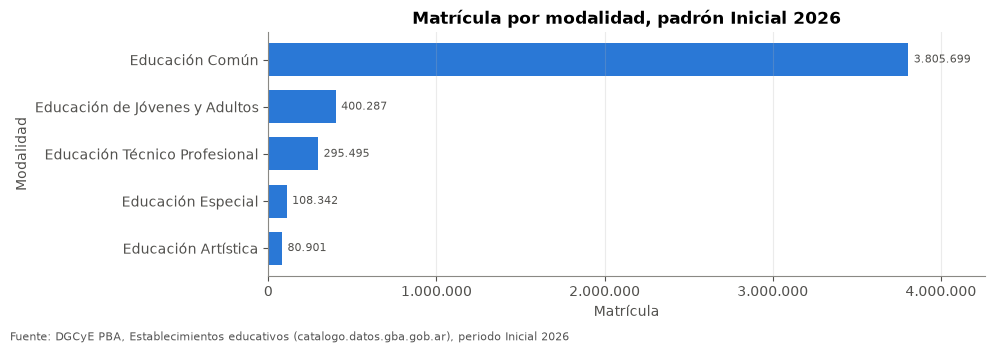

In [16]:
tabla = distribuciones["modalidad"]
u.guardar_tabla(tabla, "01_distribucion_modalidad")
display(tabla)
u.grafico_barras_h(tabla.loc[tabla["matricula"] > 0, "matricula"], "Matrícula por modalidad, padrón Inicial 2026",
                   "Matrícula", "Modalidad", "01_matricula_por_modalidad", FUENTE)
plt.show()

**Nivel**

,ofertas,establecimientos,matricula,atendidos_servicios,secciones,pct_matricula
nivel,,,,,,
Nivel Secundario,5354,5298,1820517,0,72449,38.81
Nivel Primario,7429,7429,1680279,0,71953,35.82
Nivel Inicial,6097,6097,569562,0,31117,12.14
Nivel Superior,622,622,272705,0,9922,5.81
Formación Profesional,608,608,196559,0,9495,4.19
Plan Fines (Trayectos y Deudores),165,165,54653,0,2720,1.17
Formación Integral,576,576,46761,0,0,1.0
Cursos y Talleres,93,93,26367,0,1666,0.56
Ciclo Medio,50,50,15361,0,669,0.33


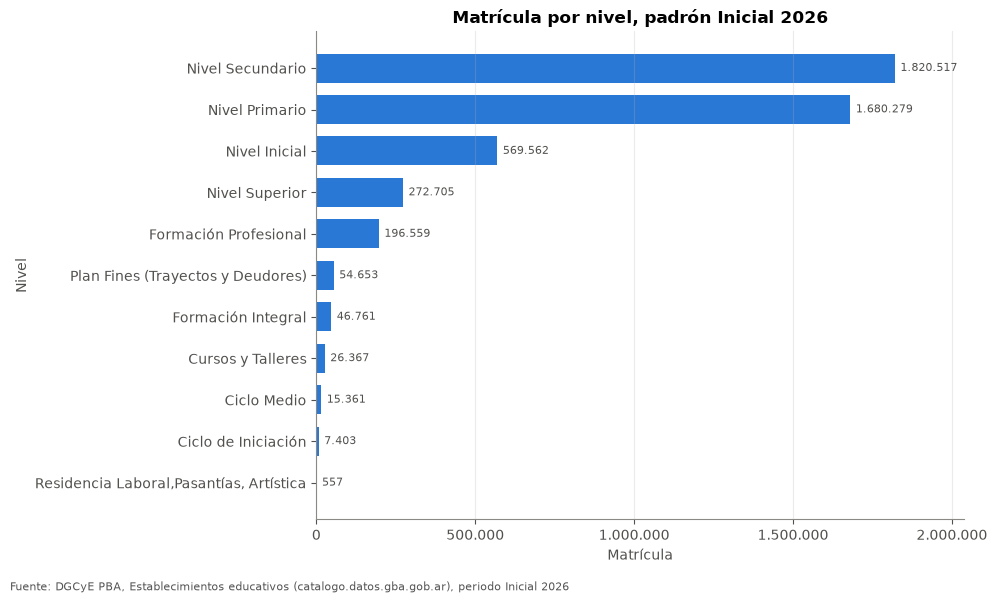

In [17]:
tabla = distribuciones["nivel"]
u.guardar_tabla(tabla, "01_distribucion_nivel")
display(tabla)
u.grafico_barras_h(tabla.loc[tabla["matricula"] > 0, "matricula"], "Matrícula por nivel, padrón Inicial 2026",
                   "Matrícula", "Nivel", "01_matricula_por_nivel", FUENTE)
plt.show()

**Sector**

,ofertas,establecimientos,matricula,atendidos_servicios,secciones,pct_matricula
sector,,,,,,
Estatal,15386,14284,3322871,185783,155666,70.84
Privado,6089,5454,1367853,1091,53249,29.16


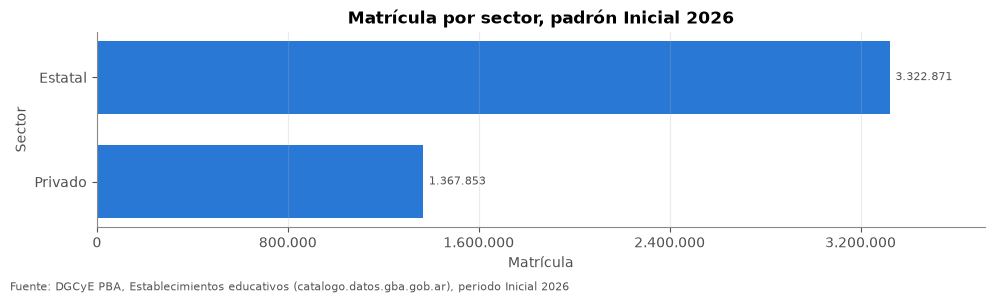

In [18]:
tabla = distribuciones["sector"]
u.guardar_tabla(tabla, "01_distribucion_sector")
display(tabla)
u.grafico_barras_h(tabla.loc[tabla["matricula"] > 0, "matricula"], "Matrícula por sector, padrón Inicial 2026",
                   "Matrícula", "Sector", "01_matricula_por_sector", FUENTE)
plt.show()

**Ámbito**

,ofertas,establecimientos,matricula,atendidos_servicios,secciones,pct_matricula
ambito,,,,,,
Urbano,18394,16697,4576575,181105,200315,97.57
Rural Disperso,1967,1958,58265,0,4368,1.24
Rural Agrupado,1107,1076,55771,5769,4224,1.19
Itinerante,7,7,113,0,8,0.0


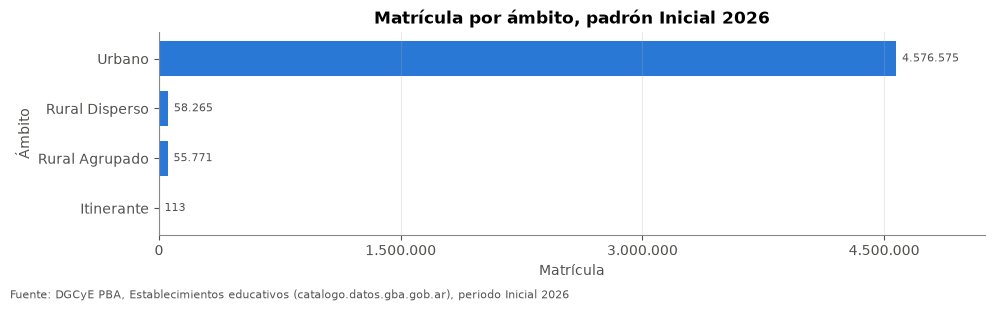

In [19]:
tabla = distribuciones["ambito"]
u.guardar_tabla(tabla, "01_distribucion_ambito")
display(tabla)
u.grafico_barras_h(tabla.loc[tabla["matricula"] > 0, "matricula"], "Matrícula por ámbito, padrón Inicial 2026",
                   "Matrícula", "Ámbito", "01_matricula_por_ambito", FUENTE)
plt.show()

**Dependencia**

,ofertas,establecimientos,matricula,atendidos_servicios,secciones,pct_matricula
dependencia,,,,,,
Oficial,14826,13758,3210467,184870,150585,68.44
Privada,6089,5454,1367853,1091,53249,29.16
Municipal,489,462,75867,913,3709,1.62
Nacional,55,48,22930,0,884,0.49
Otros Organismos,16,16,13607,0,488,0.29


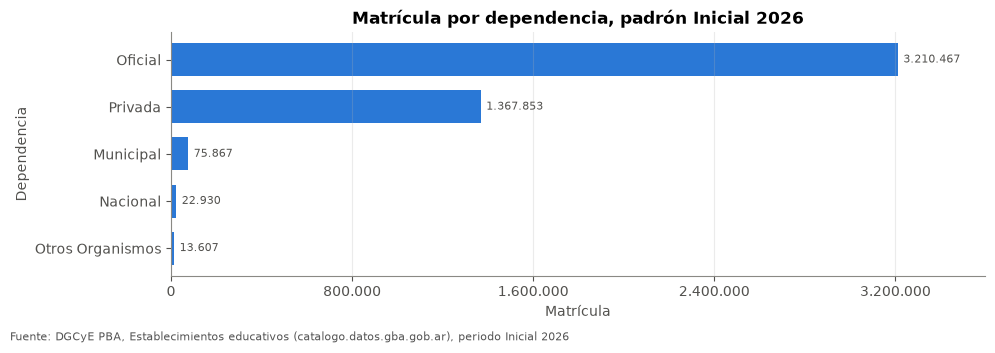

In [20]:
tabla = distribuciones["dependencia"]
u.guardar_tabla(tabla, "01_distribucion_dependencia")
display(tabla)
u.grafico_barras_h(tabla.loc[tabla["matricula"] > 0, "matricula"], "Matrícula por dependencia, padrón Inicial 2026",
                   "Matrícula", "Dependencia", "01_matricula_por_dependencia", FUENTE)
plt.show()

### A4. Top 10 establecimientos por matrícula

Matrícula por establecimiento = suma de la matrícula del sistema de todas sus ofertas (niveles × modalidades). Los C.E.F. y C.E.C. no entran en el ranking porque no tienen matrícula propia (ver la nota debajo del gráfico).

,establecimiento_nombre,municipio_nombre,sector,ofertas,niveles,matricula
establecimiento_id,,,,,,
65912,ESCUELA SUPERIOR DE EDUCACIÓN TÉCNICO PROFESIONAL,Lanús,Estatal,1,Nivel Superior,6767
24261,ESCUELA SUPERIOR DE FORMACIÓN EN SALUD,La Plata,Estatal,1,Nivel Superior,6466
3240,"CENTRO EDUCATIVO NIVEL SECUNDARIO Nº451 ""ELVIR...",General Pueyrredón,Estatal,2,"Nivel Secundario, Plan Fines (Trayectos y Deud...",3918
5853,INSTITUTO SUPERIOR DE FORMACIÓN DOCENTE N° 29,Merlo,Estatal,1,Nivel Superior,3698
24145,INSTITUTO SUPERIOR DE FORMACIÓN TÉCNICA Nº6005...,Berazategui,Estatal,1,Nivel Superior,3612
5407,INSTITUTO SUPERIOR DE FORMACIÓN DOCENTE N° 56,La Matanza,Estatal,1,Nivel Superior,3383
2475,INSTITUTO SUPERIOR DE FORMACIÓN DOCENTE N° 35 ...,Esteban Echeverría,Estatal,1,Nivel Superior,3320
6064,INSTITUTO SUPERIOR DE FORMACIÓN DOCENTE N° 21 ...,Moreno,Estatal,1,Nivel Superior,3107
5323,"ESCUELA DE ARTE Nº1 ""LEOPOLDO MARECHAL""",La Matanza,Estatal,2,"Ciclo Medio, Nivel Superior",3056


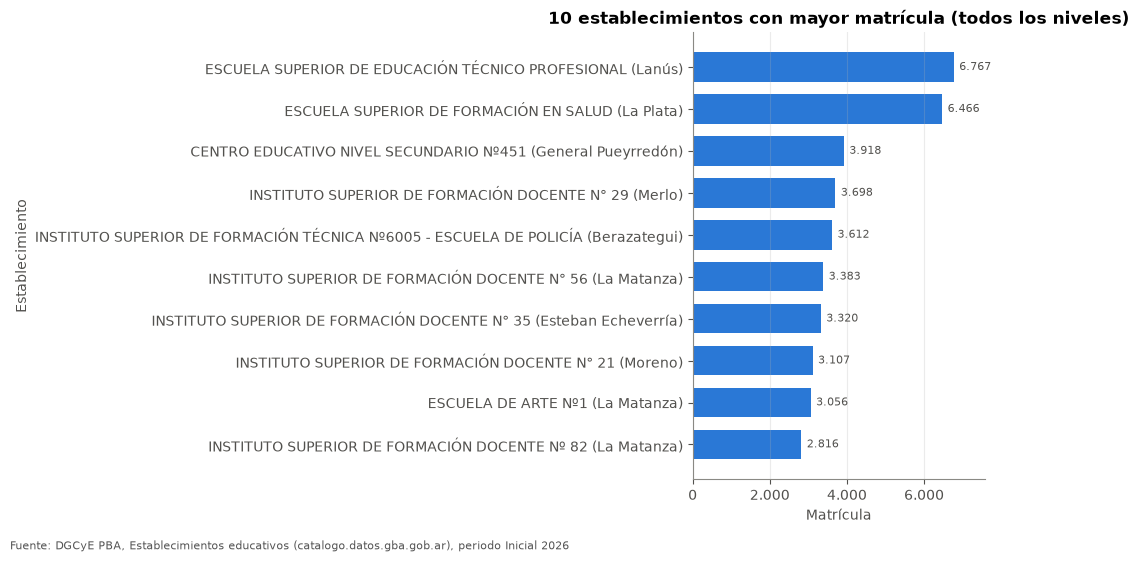

In [21]:
def agregar_por_establecimiento(df):
    return df.groupby("establecimiento_id").agg(
        establecimiento_nombre=("establecimiento_nombre", "first"),
        municipio_nombre=("municipio_nombre", "first"),
        sector=("sector", "first"),
        ofertas=("nivel", "size"),
        niveles=("nivel", lambda s: ", ".join(sorted(s.unique()))),
        matricula=("matricula_sistema", "sum"),
    )


def etiqueta_establecimiento(tabla):
    # Nombre institucional sin el nombre propio entre comillas (para que entre en el eje)
    nombres = tabla["establecimiento_nombre"].str.split('"').str[0].str.strip()
    return nombres + " (" + tabla["municipio_nombre"] + ")"


df_por_establecimiento = agregar_por_establecimiento(df_analisis)
top10_establecimientos = df_por_establecimiento.nlargest(10, "matricula")
u.guardar_tabla(top10_establecimientos, "01_top10_establecimientos_matricula")
display(top10_establecimientos)

u.grafico_barras_h(
    top10_establecimientos.set_index(etiqueta_establecimiento(top10_establecimientos))["matricula"],
    "10 establecimientos con mayor matrícula (todos los niveles)",
    "Matrícula", "Establecimiento", "01_top10_establecimientos_matricula", FUENTE,
)
plt.show()

In [22]:
# Servicios que habrían entrado al top 10 si se sumaran sus alumnos atendidos
matricula_cruda = df_analisis.groupby("establecimiento_id")["matricula"].sum()
top10_crudo = matricula_cruda.nlargest(10).index
servicios_que_salieron = (
    df_analisis[df_analisis["establecimiento_id"].isin(top10_crudo) & es_servicio]
    [["establecimiento_id", "establecimiento_nombre", "municipio_nombre", "nivel", "matricula"]]
    .sort_values("matricula", ascending=False)
)
u.guardar_tabla(servicios_que_salieron, "01_top10_servicios_excluidos", index=False)
servicios_que_salieron

,establecimiento_id,establecimiento_nombre,municipio_nombre,nivel,matricula
2949,3186,CENTRO DE EDUCACIÓN FÍSICA Nº1,General Pueyrredón,Educación Física (C.E.F.),4629
113,77,"CENTRO DE EDUCACIÓN FÍSICA Nº 2 ""MAESTRO ISAUR...",La Plata,Educación Física (C.E.F.),3488
9038,9670,"CENTRO DE EDUCACIÓN FÍSICA Nº123 ""JORGE NEWBERY""",Tres de Febrero,Educación Física (C.E.F.),3335


<!-- verificado 2026-10-21, hash datos: d62f13c, id: md-top10-nota -->
**Nota al ranking.** Si se sumaran los alumnos atendidos, entrarían al top 10 tres C.E.F., que no tienen matrícula propia y por eso no se comparan con escuelas: el C.E.F. Nº1 de General Pueyrredón (4.629 alumnos atendidos), el C.E.F. Nº 2 "Maestro Isauro Arancibia" de La Plata (3.488) y el C.E.F. Nº123 "Jorge Newbery" de Tres de Febrero (3.335). Ningún C.E.C. llega al top 10.

**Top 10 por matrícula de Nivel Secundario**: suma de Educación Común y Educación Técnico Profesional. En este padrón no existe una modalidad "Agraria": las escuelas secundarias agrarias (EESA) figuran como Técnico Profesional (y unas pocas como Común), **por eso están incluidas** en este ranking.
Quedan fuera los secundarios de Jóvenes y Adultos (CENS) y de Educación Artística: la celda los cuantifica. Ver `DOCUMENTACION.md` §5.

Matrícula de Nivel Secundario por modalidad:
modalidad
Educación Común                   1.476.041
Educación Técnico Profesional       250.881
Educación de Jóvenes y Adultos       89.211
Educación Artística                   4.384

Secundarias agrarias por modalidad: {'Educación Técnico Profesional': 108, 'Educación Común': 3}


,establecimiento_nombre,municipio_nombre,sector,ofertas,niveles,matricula
establecimiento_id,,,,,,
5910,"ESCUELA DE EDUCACIÓN SECUNDARIA TÉCNICA Nº2 ""R...",Merlo,Estatal,1,Nivel Secundario,2286
9609,"ESCUELA DE EDUCACIÓN SECUNDARIA TÉCNICA Nº1 ""C...",Escobar,Estatal,1,Nivel Secundario,2253
2500,"ESCUELA DE EDUCACIÓN SECUNDARIA Nº1 ""NACIONES ...",Esteban Echeverría,Estatal,1,Nivel Secundario,2243
2503,"ESCUELA DE EDUCACIÓN SECUNDARIA Nº2 ""O. E .A.""",Ezeiza,Estatal,1,Nivel Secundario,2124
5904,"ESCUELA DE EDUCACIÓN SECUNDARIA Nº16 ""MANUEL B...",Merlo,Estatal,1,Nivel Secundario,1870
4879,"ESCUELA DE EDUCACIÓN SECUNDARIA TÉCNICA Nº5 ""2...",Lomas de Zamora,Estatal,1,Nivel Secundario,1846
5909,"ESCUELA DE EDUCACIÓN SECUNDARIA TÉCNICA Nº1 ""I...",Merlo,Estatal,1,Nivel Secundario,1832
6133,"ESCUELA DE EDUCACIÓN SECUNDARIA TÉCNICA Nº2 ""G...",Moreno,Estatal,1,Nivel Secundario,1756
3359,"ESCUELA DE EDUCACIÓN SECUNDARIA TÉCNICA Nº1 ""J...",General Rodríguez,Estatal,1,Nivel Secundario,1731


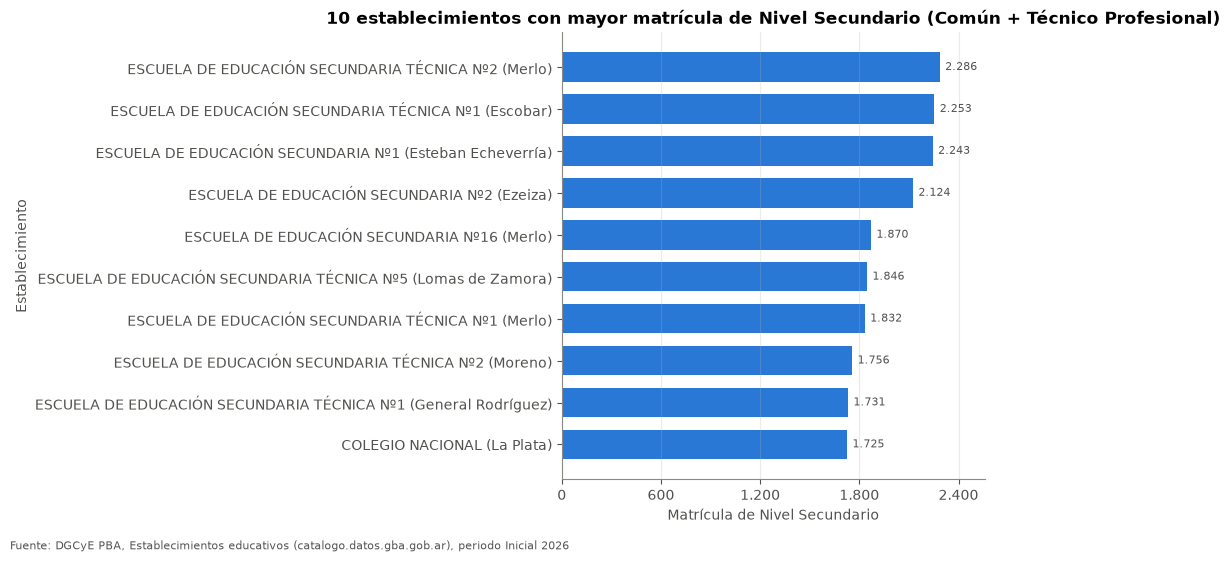

In [23]:
MODALIDADES_SECUNDARIO = ["Educación Común", "Educación Técnico Profesional"]

secundario = df_analisis[df_analisis["nivel"] == "Nivel Secundario"]
print("Matrícula de Nivel Secundario por modalidad:")
print(secundario.groupby("modalidad")["matricula"].sum().sort_values(ascending=False).map(u._miles_ar).to_string())
agrarias = secundario["tipo_organizacion"].str.contains("AGRARIA", na=False)
print("\nSecundarias agrarias por modalidad:", secundario.loc[agrarias, "modalidad"].value_counts().to_dict())

df_secundario_establecimiento = agregar_por_establecimiento(
    secundario[secundario["modalidad"].isin(MODALIDADES_SECUNDARIO)]
)
top10_secundario = df_secundario_establecimiento.nlargest(10, "matricula")
u.guardar_tabla(top10_secundario, "01_top10_establecimientos_secundario")
display(top10_secundario)

u.grafico_barras_h(
    top10_secundario.set_index(etiqueta_establecimiento(top10_secundario))["matricula"],
    "10 establecimientos con mayor matrícula de Nivel Secundario (Común + Técnico Profesional)",
    "Matrícula de Nivel Secundario", "Establecimiento", "01_top10_establecimientos_secundario", FUENTE,
)
plt.show()

### A5. Municipios: matrícula y establecimientos

Ranking sobre los municipios presentes en el padrón. La tabla completa se guarda en `outputs/01_municipios.csv`.

In [24]:
df_municipios = df_analisis.groupby("municipio_nombre").agg(
    municipio_id=("municipio_id", "first"),
    region_educativa=("region_educativa", "first"),
    establecimientos=("establecimiento_id", "nunique"),
    ofertas=("establecimiento_id", "size"),
    matricula=("matricula_sistema", "sum"),
    secciones=("secciones", "sum"),
).sort_values("matricula", ascending=False)
u.guardar_tabla(df_municipios, "01_municipios")

print("Top 10 por matrícula")
display(df_municipios.head(10))
print("Top 10 por cantidad de establecimientos")
display(df_municipios.nlargest(10, "establecimientos"))

Top 10 por matrícula


,municipio_id,region_educativa,establecimientos,ofertas,matricula,secciones
municipio_nombre,,,,,,
La Matanza,06427,Región 3,1206,1320,411743,17069
La Plata,06441,Región 1,850,927,237803,10132
Lomas de Zamora,06490,Región 2,663,716,197426,8332
General Pueyrredón,06357,Región 19,674,748,179821,8049
Moreno,06560,Región 9,438,494,170029,5967
Quilmes,06658,Región 4,532,575,163578,6616
Almirante Brown,06028,Región 5,505,540,150665,6078
Merlo,06539,Región 8,421,447,150446,5839
Florencio Varela,06274,Región 4,346,370,134159,5110


Top 10 por cantidad de establecimientos


,municipio_id,region_educativa,establecimientos,ofertas,matricula,secciones
municipio_nombre,,,,,,
La Matanza,06427,Región 3,1206,1320,411743,17069
La Plata,06441,Región 1,850,927,237803,10132
General Pueyrredón,06357,Región 19,674,748,179821,8049
Lomas de Zamora,06490,Región 2,663,716,197426,8332
Quilmes,06658,Región 4,532,575,163578,6616
Almirante Brown,06028,Región 5,505,540,150665,6078
Moreno,06560,Región 9,438,494,170029,5967
Lanús,06434,Región 2,423,463,111574,4826
Merlo,06539,Región 8,421,447,150446,5839


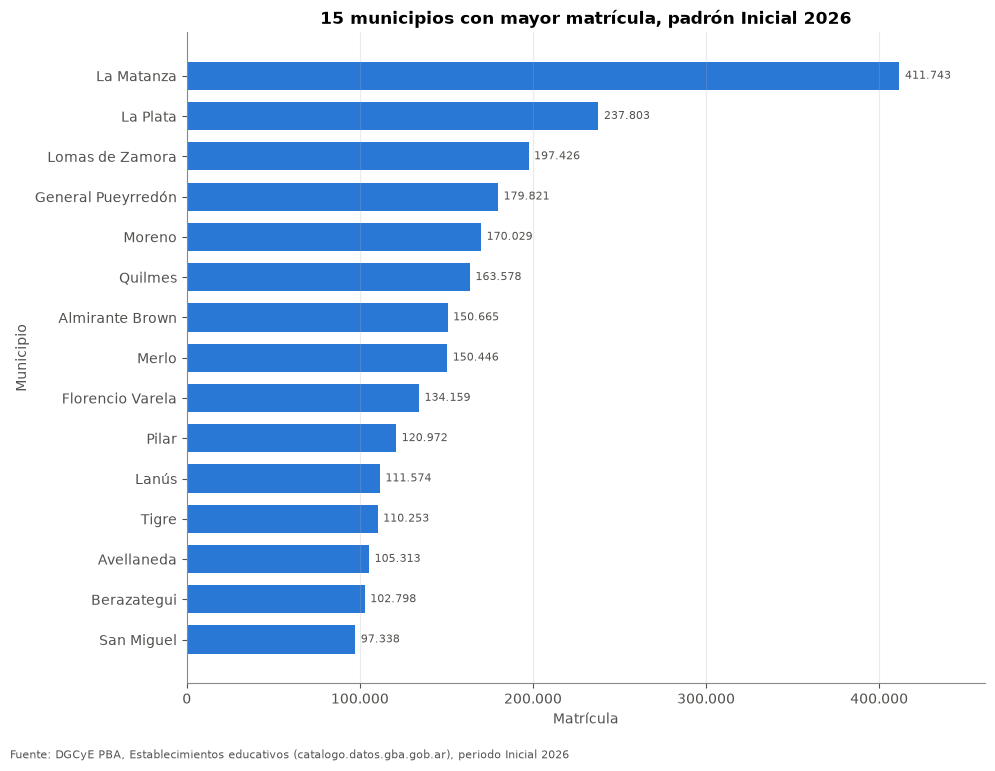

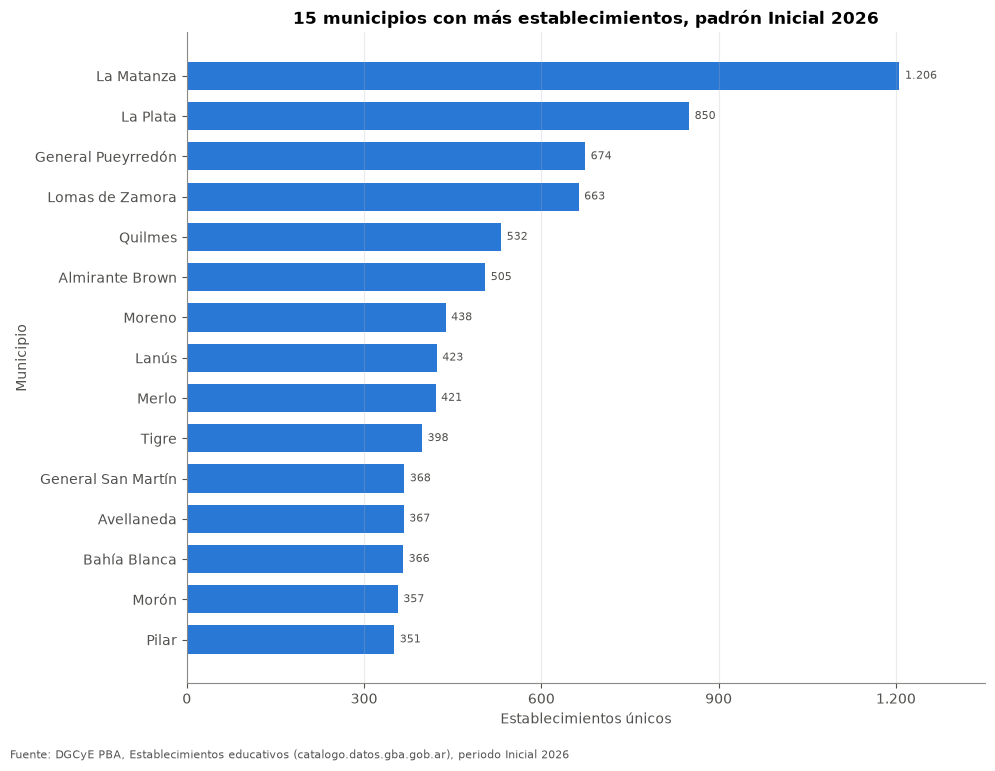

In [25]:
u.grafico_barras_h(df_municipios["matricula"].head(15),
                   "15 municipios con mayor matrícula, padrón Inicial 2026",
                   "Matrícula", "Municipio", "01_top15_municipios_matricula", FUENTE)
plt.show()

u.grafico_barras_h(df_municipios["establecimientos"].nlargest(15),
                   "15 municipios con más establecimientos, padrón Inicial 2026",
                   "Establecimientos únicos", "Municipio", "01_top15_municipios_establecimientos", FUENTE)
plt.show()

### A6. Regiones educativas

Están las 25 regiones, así que el ranking cubre toda la provincia.
**Ojo**: ordena por *matrícula relevada en el padrón*, no por población escolar total ni por población en edad escolar. No debe leerse como "región más poblada".

,municipios,establecimientos,ofertas,matricula,secciones
region_numero,,,,,
Región 9,4,1196,1331,436874,16182
Región 2,3,1453,1582,414313,17670
Región 3,1,1206,1320,411743,17069
Región 4,3,1215,1302,400535,16041
Región 5,5,1122,1205,375634,14324
Región 1,6,1216,1318,311828,13916
Región 11,5,1004,1103,292009,11663
Región 8,3,938,1032,280060,11680
Región 6,4,1187,1291,277924,13013


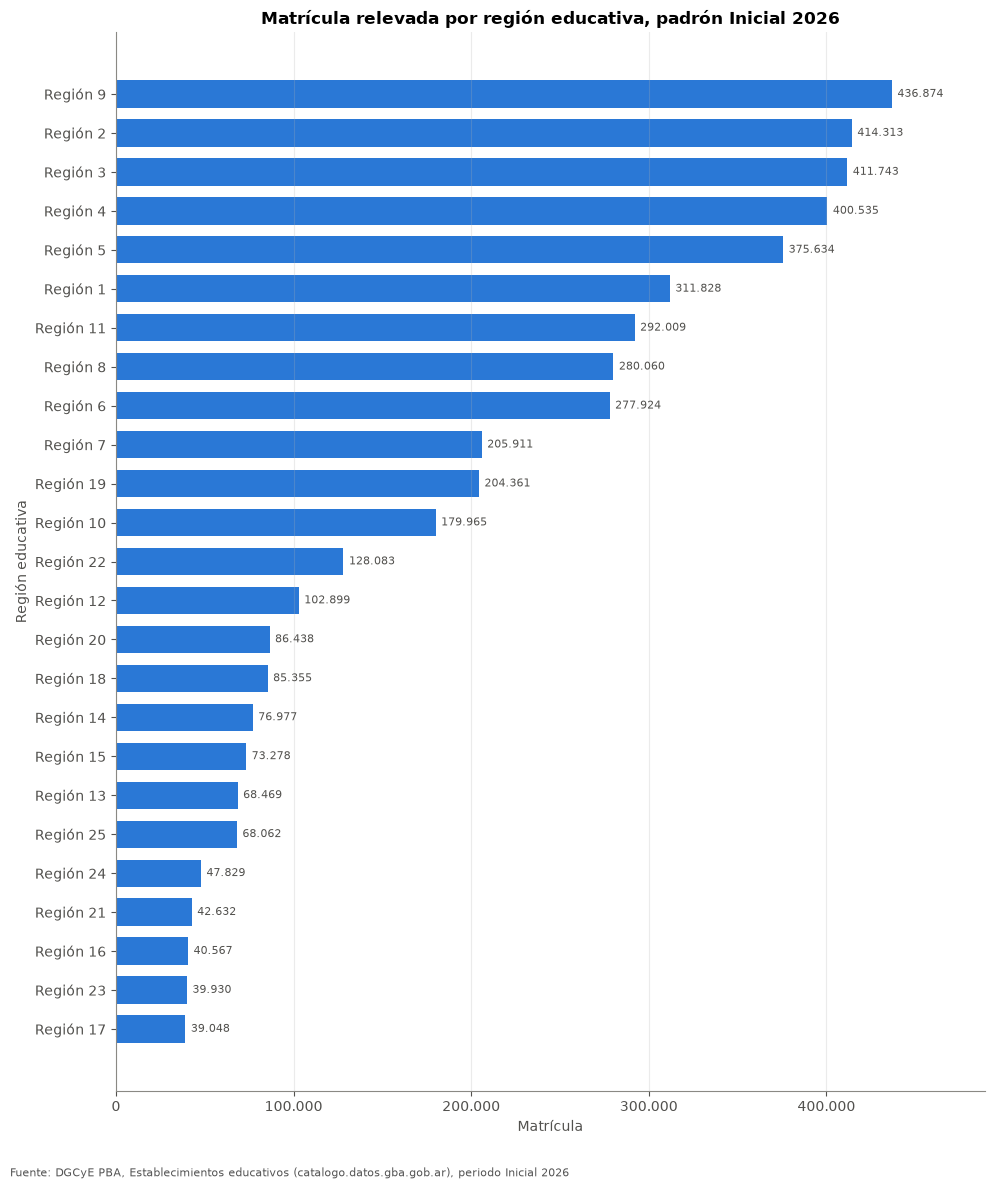

In [26]:
df_regiones = df_analisis.groupby("region_numero").agg(
    municipios=("municipio_nombre", "nunique"),
    establecimientos=("establecimiento_id", "nunique"),
    ofertas=("establecimiento_id", "size"),
    matricula=("matricula_sistema", "sum"),
    secciones=("secciones", "sum"),
).sort_values("matricula", ascending=False)
df_regiones.index = "Región " + df_regiones.index.astype(str)
u.guardar_tabla(df_regiones, "01_regiones")
display(df_regiones)

u.grafico_barras_h(df_regiones["matricula"], "Matrícula relevada por región educativa, padrón Inicial 2026",
                   "Matrícula", "Región educativa", "01_regiones_matricula", FUENTE)
plt.show()

### A7. Distribución territorial

Un punto por establecimiento único, con sus coordenadas del padrón. Es un scatter de matplotlib (sin geopandas ni capa de límites), a título de ubicación general.

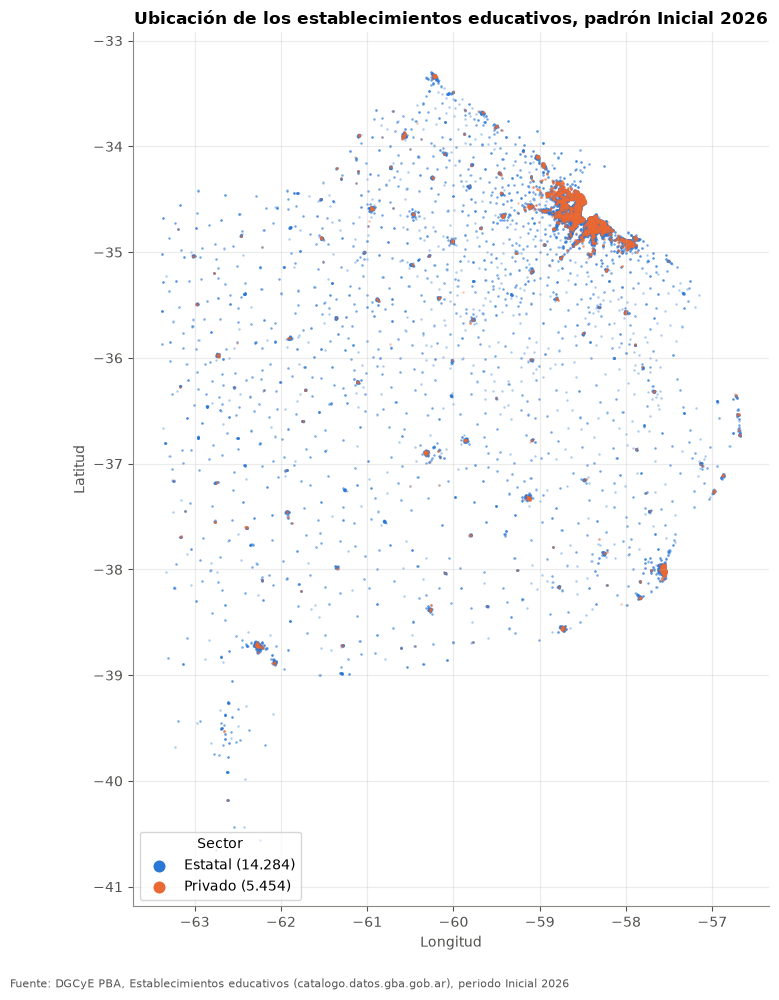

In [27]:
df_mapa = df_analisis.drop_duplicates("establecimiento_id")

fig, ax = plt.subplots(figsize=(9, 10))
for color, (sector, grupo) in zip(u.PALETA, df_mapa.groupby("sector")):
    ax.scatter(grupo["longitud"], grupo["latitud"], s=3, alpha=0.4, color=color, linewidths=0,
               label=f"{sector} ({u._miles_ar(len(grupo))})")

ax.set_aspect(1 / np.cos(np.deg2rad(df_mapa["latitud"].mean())))
ax.set_title("Ubicación de los establecimientos educativos, padrón Inicial 2026")
ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")
leyenda = ax.legend(title="Sector", markerscale=5, loc="lower left")
for marcador in leyenda.legend_handles:
    marcador.set_alpha(1)
u.guardar_figura(fig, "01_mapa_establecimientos", FUENTE)
plt.show()

# Parte B — La Plata como caso de estudio

Recorte sobre el mismo universo de análisis (Inicial 2026, sin las filas de la sección 4), **estatal y privado juntos**.

#### Calidad de datos del recorte: apertura estatal / privado

In [28]:
df_la_plata = df_analisis[df_analisis["municipio_nombre"] == "La Plata"].copy()

print("Registros:", len(df_la_plata))
print("Establecimientos únicos:", df_la_plata["establecimiento_id"].nunique())

apertura_sector = df_la_plata.groupby("sector").agg(
    ofertas=("establecimiento_id", "size"),
    establecimientos=("establecimiento_id", "nunique"),
    matricula=("matricula_sistema", "sum"),
)
apertura_sector["pct_establecimientos"] = (apertura_sector["establecimientos"] / apertura_sector["establecimientos"].sum() * 100).round(1)
apertura_sector["pct_matricula"] = (apertura_sector["matricula"] / apertura_sector["matricula"].sum() * 100).round(1)
u.guardar_tabla(apertura_sector, "01_la_plata_apertura_sector")
apertura_sector

Registros: 927
Establecimientos únicos: 850


,ofertas,establecimientos,matricula,pct_establecimientos,pct_matricula
sector,,,,,
Estatal,562,509,162936,59.9,68.5
Privado,365,341,74867,40.1,31.5


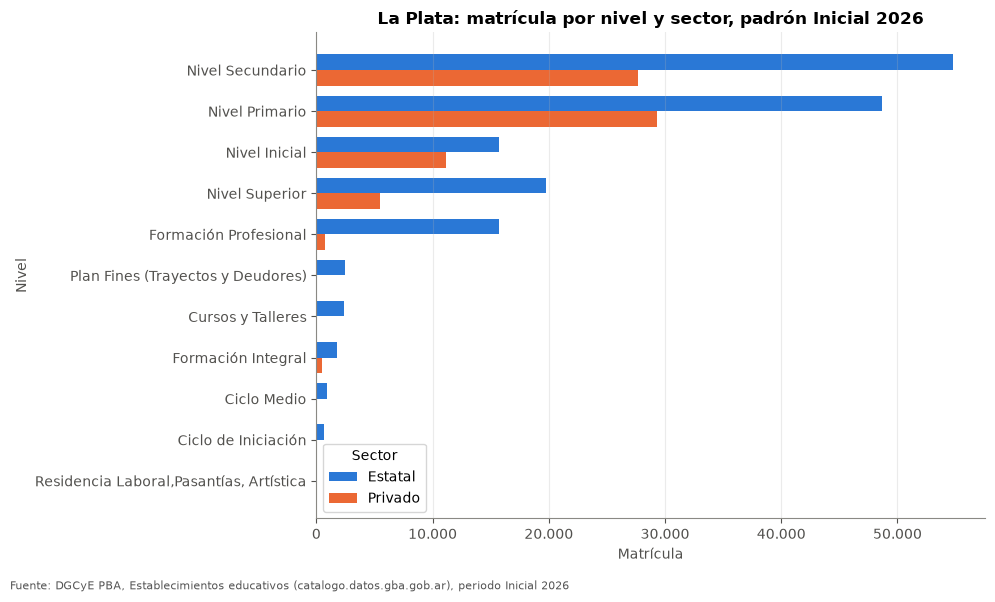

In [29]:
matricula_nivel_sector = (
    df_la_plata.pivot_table(index="nivel", columns="sector", values="matricula_sistema", aggfunc="sum", fill_value=0)
)
matricula_nivel_sector = matricula_nivel_sector[matricula_nivel_sector.sum(axis=1) > 0]
matricula_nivel_sector = matricula_nivel_sector.loc[matricula_nivel_sector.sum(axis=1).sort_values().index]

fig, ax = plt.subplots(figsize=(10, 6))
alto = 0.38
posiciones = np.arange(len(matricula_nivel_sector))
for desplazamiento, color, sector in zip([alto / 2, -alto / 2], u.PALETA, matricula_nivel_sector.columns):
    ax.barh(posiciones + desplazamiento, matricula_nivel_sector[sector], height=alto, color=color, label=sector)
ax.set_yticks(posiciones, matricula_nivel_sector.index)
ax.set_title("La Plata: matrícula por nivel y sector, padrón Inicial 2026")
ax.set_xlabel("Matrícula")
ax.set_ylabel("Nivel")
ax.xaxis.set_major_formatter(u.formato_miles())
ax.grid(axis="y", visible=False)
ax.legend(title="Sector")
u.guardar_figura(fig, "01_la_plata_matricula_nivel_sector", FUENTE)
plt.show()

¿Cómo se distribuyen los establecimientos educativos de La Plata según nivel, modalidad y sector?

In [30]:
establecimientos_por_nivel = (
    df_la_plata
    .groupby("nivel")["establecimiento_id"]
    .nunique()
    .sort_values(ascending=False)
)

establecimientos_por_nivel

nivel
Nivel Primario                             280
Nivel Inicial                              257
Nivel Secundario                           242
Formación Profesional                       51
Nivel Superior                              49
Formación Integral                          29
Plan Fines (Trayectos y Deudores)            7
Ciclo Medio                                  3
Ciclo de Iniciación                          3
Cursos y Talleres                            2
Residencia Laboral,Pasantías, Artística      2
Educación Física (C.E.F.)                    1
Name: establecimiento_id, dtype: int64

In [31]:
establecimientos_por_modalidad = (
    df_la_plata
    .groupby("modalidad")["establecimiento_id"]
    .nunique()
    .sort_values(ascending=False)
)

establecimientos_por_modalidad

modalidad
Educación Común                   661
Educación de Jóvenes y Adultos    128
Educación Especial                 31
Educación Técnico Profesional      23
Educación Artística                 8
Educación Física                    1
Name: establecimiento_id, dtype: int64

In [32]:
df_la_plata.groupby("sector")["establecimiento_id"].nunique().sort_values(ascending=False)

sector
Estatal    509
Privado    341
Name: establecimiento_id, dtype: int64

In [33]:
df_la_plata.nunique().sort_values()

municipio_id                     1
municipio_nombre                 1
region_educativa                 1
area                             1
periodo                          1
region_numero                    1
alumnos_atendidos_servicios      2
sector                           2
sede_axo_ext                     3
categoria                        4
ambito                           4
desfavorabilidad                 4
dependencia                      5
modalidad                        6
subvencion                       8
depend_func                     12
nivel                           12
anexo                           12
tipo_organizacion               25
turnos                          29
secciones                       58
rpv                            199
mujeres                        325
varones                        328
matricula                      470
matricula_sistema              470
cui                            519
telefono                       655
nro_escuela         

In [34]:
columnas_categoricas = [
    "modalidad",
    "nivel",
    "sector",
    "dependencia",
    "desfavorabilidad",
    "anexo",
    "categoria",
    "depend_func",
    "tipo_organizacion"
]

for col in columnas_categoricas:
    print(f"\n--- {col} ---")
    print(df_la_plata[col].value_counts(dropna=False))


--- modalidad ---
modalidad
Educación Común                   669
Educación de Jóvenes y Adultos    135
Educación Especial                 85
Educación Técnico Profesional      23
Educación Artística                14
Educación Física                    1
Name: count, dtype: int64

--- nivel ---
nivel
Nivel Primario                             280
Nivel Inicial                              257
Nivel Secundario                           243
Formación Profesional                       51
Nivel Superior                              49
Formación Integral                          29
Plan Fines (Trayectos y Deudores)            7
Ciclo Medio                                  3
Ciclo de Iniciación                          3
Cursos y Talleres                            2
Residencia Laboral,Pasantías, Artística      2
Educación Física (C.E.F.)                    1
Name: count, dtype: int64

--- sector ---
sector
Estatal    562
Privado    365
Name: count, dtype: int64

--- dependencia ---
depend

<!-- verificado 2026-10-21, hash datos: d62f13c, id: md-lp-niveles -->
¿Por qué tenemos 850 establecimientos únicos, pero la suma de establecimientos por nivel da 926?

La respuesta está en que un mismo establecimiento puede ofrecer varios niveles. Por ejemplo:
Establecimiento 71
Inicial
Primario
Formación Profesional
Formación Integral

In [35]:
# cuántos niveles ofrece cada establecimiento
niveles_por_establecimiento = (
    df_la_plata
    .groupby("establecimiento_id")["nivel"]
    .nunique()
)

niveles_por_establecimiento.value_counts().sort_index()

nivel
1    803
2     21
3     23
4      3
Name: count, dtype: int64

In [36]:
df_la_plata.groupby("establecimiento_id")["nivel"].agg(list).head(20)

establecimiento_id
1     [Nivel Superior, Ciclo Medio, Ciclo de Iniciac...
2                                   [Cursos y Talleres]
3                                   [Cursos y Talleres]
7     [Ciclo de Iniciación, Nivel Superior, Ciclo Me...
8     [Nivel Superior, Ciclo de Iniciación, Ciclo Me...
9                                      [Nivel Superior]
10                                     [Nivel Primario]
11                                     [Nivel Primario]
13                                     [Nivel Primario]
14                                     [Nivel Primario]
15                                     [Nivel Primario]
16                                     [Nivel Primario]
17                                     [Nivel Primario]
18                                     [Nivel Primario]
19                                     [Nivel Primario]
20                                     [Nivel Primario]
21                                     [Nivel Primario]
22                           

¿Qué información cuantitativa tenemos de esos establecimientos?

Especialmente:

matricula
varones
mujeres
secciones

In [37]:
df_la_plata[
    ["matricula", "varones", "mujeres", "secciones"]
].describe()

,matricula,varones,mujeres,secciones
count,927.0,927.0,927.0,927.0
mean,260.292341,124.416397,135.875944,10.929881
std,349.472113,137.193866,249.956041,12.682978
min,1.0,0.0,0.0,0.0
25%,83.0,39.5,37.0,4.0
50%,160.0,77.0,79.0,8.0
75%,337.0,166.0,173.0,12.5
max,6466.0,1296.0,5699.0,165.0


<!-- verificado 2026-10-21, hash datos: d62f13c, id: md-lp-media -->
La diferencia entre media (260) y mediana (160) es enorme.

Eso nos dice que probablemente tenemos una distribución muy sesgada hacia la derecha: unas pocas unidades educativas tienen matrículas muy grandes y empujan la media hacia arriba.

In [38]:
# ¿cuántos datos faltan?
df_la_plata[
    ["matricula", "varones", "mujeres", "secciones"]
].isna().sum()

matricula    0
varones      0
mujeres      0
secciones    0
dtype: int64

In [39]:
# creación de la columna de varones + mujeres
df_la_plata["suma_genero"] = (
    df_la_plata["varones"] + df_la_plata["mujeres"]
)

(df_la_plata["matricula"] == df_la_plata["suma_genero"]).value_counts()

True    927
Name: count, dtype: Int64

In [40]:
df_la_plata["diferencia_matricula"] = (
    df_la_plata["matricula"] - df_la_plata["suma_genero"]
)

df_la_plata["diferencia_matricula"].value_counts().sort_index()

diferencia_matricula
0    927
Name: count, dtype: Int64

¿cuánta matrícula hay realmente en el sistema educativo estatal y privado registrado de La Plata?

In [41]:
# total matricula 
df_la_plata.groupby("nivel").agg(
    matricula=("matricula_sistema", "sum")
).sort_values("matricula", ascending=False).sum()

matricula    237803
dtype: Int64

In [42]:
df_la_plata.groupby("nivel").agg(
    establecimientos=("establecimiento_id", "nunique"),
    secciones=("secciones", "sum"),
    matricula=("matricula_sistema", "sum")
).sort_values("matricula", ascending=False)

,establecimientos,secciones,matricula
nivel,,,
Nivel Secundario,242,3336,82500
Nivel Primario,280,3139,77983
Nivel Inicial,257,1494,26915
Nivel Superior,49,837,25211
Formación Profesional,51,836,16486
Plan Fines (Trayectos y Deudores),7,131,2456
Cursos y Talleres,2,121,2371
Formación Integral,29,0,2247
Ciclo Medio,3,40,929


In [43]:
df_la_plata[df_la_plata["secciones"] == 0][
    [
        "establecimiento_id",
        "establecimiento_nombre",
        "nivel",
        "modalidad",
        "matricula",
        "secciones"
    ]
]

,establecimiento_id,establecimiento_nombre,nivel,modalidad,matricula,secciones
52,54,"ESCUELA ESPECIAL Nº503 ""J. J. GORRITTI""",Formación Integral,Educación Especial,76,0
53,54,"ESCUELA ESPECIAL Nº503 ""J. J. GORRITTI""",Nivel Inicial,Educación Especial,10,0
54,54,"ESCUELA ESPECIAL Nº503 ""J. J. GORRITTI""",Nivel Primario,Educación Especial,161,0
55,56,"ESCUELA ESPECIAL Nº509 ""DR. CARLOS COMETTO""",Formación Integral,Educación Especial,40,0
56,56,"ESCUELA ESPECIAL Nº509 ""DR. CARLOS COMETTO""",Nivel Inicial,Educación Especial,35,0
...,...,...,...,...,...,...
9694,10338,ESCUELA I. P. A. C. INST. PLATENSE DE ASIST P/...,Formación Integral,Educación Especial,41,0
9695,10338,ESCUELA I. P. A. C. INST. PLATENSE DE ASIST P/...,Nivel Inicial,Educación Especial,1,0
14891,17443,ESCUELA DE EDUCACIÓN TEMPRANA Nº 1,Nivel Inicial,Educación Especial,42,0
15080,17983,ESCUELA ESPECIAL CENTRO DE DIA,Formación Integral,Educación Especial,22,0


In [44]:
pd.crosstab(
    df_la_plata["modalidad"],
    df_la_plata["secciones"] == 0
)

secciones,False,True
modalidad,,
Educación Artística,14,0
Educación Común,669,0
Educación Especial,0,85
Educación Física,1,0
Educación Técnico Profesional,23,0
Educación de Jóvenes y Adultos,135,0


Matrícula total por modalidad

¿Qué modalidades concentran mayor matrícula y qué niveles explican esa concentración?

In [45]:
matricula_modalidad = (
    df_la_plata
    .groupby("modalidad")
    .agg(
        establecimientos=("establecimiento_id", "nunique"),
        matricula=("matricula_sistema", "sum")
    )
    .sort_values("matricula", ascending=False)
)

matricula_modalidad

,establecimientos,matricula
modalidad,,
Educación Común,661,178217
Educación de Jóvenes y Adultos,128,27424
Educación Técnico Profesional,23,21327
Educación Artística,8,5990
Educación Especial,31,4845
Educación Física,1,0


¿Cómo se distribuye la oferta educativa de La Plata entre modalidades y niveles?

In [46]:
matricula_modalidad_nivel = (
    df_la_plata
    .groupby(["nivel", "modalidad"])["matricula_sistema"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

matricula_modalidad_nivel

,nivel,modalidad,matricula_sistema
0,Nivel Primario,Educación Común,71882
1,Nivel Secundario,Educación Común,68047
2,Nivel Inicial,Educación Común,26567
3,Formación Profesional,Educación de Jóvenes y Adultos,16388
4,Nivel Superior,Educación Técnico Profesional,12235
5,Nivel Superior,Educación Común,11721
6,Nivel Secundario,Educación Técnico Profesional,9092
7,Nivel Secundario,Educación de Jóvenes y Adultos,4590
8,Nivel Primario,Educación de Jóvenes y Adultos,3990
9,Plan Fines (Trayectos y Deudores),Educación de Jóvenes y Adultos,2456


In [47]:
# ¿Hay duplicados exactos?
df_la_plata.duplicated().sum()

np.int64(0)

In [48]:
# Reviso si faltan coordenadas, dado que quiero eventualmente hacer análisis territorial
df_la_plata[["latitud", "longitud"]].isna().sum()

latitud     0
longitud    0
dtype: int64

In [49]:
df_la_plata[
    ["matricula", "varones", "mujeres", "secciones"]
].isna().sum()

matricula    0
varones      0
mujeres      0
secciones    0
dtype: int64

In [50]:
resumen_calidad = pd.DataFrame({
    "filas": [len(df_la_plata)],
    "establecimientos_unicos": [
        df_la_plata["establecimiento_id"].nunique()
    ],
    "duplicados_exactos": [
        df_la_plata.duplicated().sum()
    ],
    "duplicados_establecimiento_nivel": [
        df_la_plata.duplicated(
            subset=["establecimiento_id", "nivel"]
        ).sum()
    ],
    "filas_con_latitud_faltante": [
        df_la_plata["latitud"].isna().sum()
    ],
    "filas_con_longitud_faltante": [
        df_la_plata["longitud"].isna().sum()
    ]
})

resumen_calidad

,filas,establecimientos_unicos,duplicados_exactos,duplicados_establecimiento_nivel,filas_con_latitud_faltante,filas_con_longitud_faltante
0,927,850,0,1,0,0


<!-- verificado 2026-10-21, hash datos: d62f13c, id: md-lp-resumen -->
Filas del archivo original: 21.593; Columnas: 35.

Filas de La Plata: 927; Establecimientos únicos en La Plata: 850.

Las 927 filas de La Plata representan registros de establecimientos asociados a niveles o servicios educativos, no 927 escuelas necesariamente distintas. En ese recorte aparecen 850 valores únicos de establecimiento_id.
No se detectaron duplicados exactos. Sí hay 1 caso que repite la clave establecimiento_id + nivel en las 927 filas: el establecimiento 10474 (Escuela Técnica San Vicente de Paul, privada), que tiene Nivel Secundario en dos modalidades (Común y Técnico Profesional). Es el mismo fenómeno que el establecimiento 381 de Alberti: la clave única real es establecimiento_id + nivel + modalidad. Tampoco faltaban coordenadas en ese recorte.

## 4. Filas fuera del análisis

No son errores. Las ofertas "Nueva" y las de FinEs sin secciones se excluyen de conteos y rankings, porque no aportan a las distribuciones (matrícula 0 o sin secciones) y distorsionarían los promedios de matrícula por establecimiento. Los C.E.F. y C.E.C. siguen en el análisis de oferta, pero no se suman a la matrícula del sistema.

<!-- verificado 2026-10-21, hash datos: d62f13c, id: md-excluidas -->
**Ofertas con periodo "Nueva"** (115 filas): ofertas recién creadas, todavía sin matrícula ni secciones. Ninguno de esos establecimientos aparece también con periodo "Inicial 2026".

In [51]:
df_nuevas = df_establecimientos[es_nueva]
print("Filas 'Nueva':", len(df_nuevas), "| establecimientos:", df_nuevas["establecimiento_id"].nunique())
print("Matrícula total:", df_nuevas["matricula"].sum(), "| secciones totales:", df_nuevas["secciones"].sum())
print("Por sector:", df_nuevas["sector"].value_counts().to_dict())

nuevas_nivel_modalidad = pd.crosstab(df_nuevas["nivel"], df_nuevas["modalidad"], margins=True, margins_name="Total")
u.guardar_tabla(nuevas_nivel_modalidad, "01_nuevas_nivel_modalidad")
display(nuevas_nivel_modalidad)

nuevas_municipio = df_nuevas["municipio_nombre"].value_counts().head(10).rename("ofertas_nuevas")
u.guardar_tabla(nuevas_municipio.to_frame(), "01_nuevas_top10_municipios")
display(nuevas_municipio.to_frame())

Filas 'Nueva': 115 | establecimientos: 115
Matrícula total: 0 | secciones totales: 0
Por sector: {'Estatal': 95, 'Privado': 20}


modalidad,Educación Artística,Educación Común,Educación Especial,Educación Física,Educación Técnico Profesional,Educación de Jóvenes y Adultos,Total
nivel,,,,,,,
Educación Física (C.E.F.),0,0,0,1,0,0,1
Formación Integral,0,0,2,0,0,0,2
Formación Profesional,0,0,0,0,0,15,15
Nivel Inicial,0,68,0,0,0,0,68
Nivel Primario,0,8,4,0,0,3,15
Nivel Secundario,0,5,0,0,1,1,7
Nivel Superior,3,4,0,0,0,0,7
Total,3,85,6,1,1,19,115


,ofertas_nuevas
municipio_nombre,
Avellaneda,30
La Plata,7
Lomas de Zamora,5
General Pueyrredón,4
Tigre,4
Berazategui,3
Florencio Varela,3
San Pedro,3
General San Martín,2


**Plan FinEs con secciones = 0 y matrícula > 0** (3 filas). Es un caso distinto: hay matrícula real pero no hay secciones asignadas, probablemente porque FinEs no se organiza en secciones. Mismo tratamiento: fuera de los conteos y reportadas acá.

In [52]:
df_fines_sin_secciones = df_establecimientos.loc[
    es_sin_secciones,
    ["municipio_nombre", "establecimiento_id", "establecimiento_nombre", "nivel", "modalidad", "sector", "matricula", "secciones"],
]
u.guardar_tabla(df_fines_sin_secciones, "01_fines_sin_secciones", index=False)
print("Matrícula excluida:", df_fines_sin_secciones["matricula"].sum())
df_fines_sin_secciones

Matrícula excluida: 1101


,municipio_nombre,establecimiento_id,establecimiento_nombre,nivel,modalidad,sector,matricula,secciones
20271,Berazategui,102251,CENTRO EDUCATIVO DE NIVEL SECUNDARIO Nº454,Plan Fines (Trayectos y Deudores),Educación de Jóvenes y Adultos,Estatal,580,0
20364,José C. Paz,102334,CENTRO EDUCATIVO DE NIVEL SECUNDARIO Nº452,Plan Fines (Trayectos y Deudores),Educación de Jóvenes y Adultos,Estatal,415,0
20367,José C. Paz,102335,CENTRO EDUCATIVO DE NIVEL SECUNDARIO Nº453,Plan Fines (Trayectos y Deudores),Educación de Jóvenes y Adultos,Estatal,106,0


<!-- verificado 2026-10-21, hash datos: d62f13c, id: md-servicios -->
**Servicios sin matrícula propia: C.E.F. y C.E.C.** (197 + 187 = 384 servicios). Atienden a alumnos que ya están matriculados en otra escuela; su "matrícula" son alumnos atendidos. Se mantienen en el análisis de oferta y **no se suman** a la matrícula del sistema: los C.E.F. suman 158.857 alumnos atendidos y los C.E.C., 28.017.

Verificación (se guarda en `outputs/01_verificacion_servicios_cui.csv` y `outputs/01_verificacion_servicios_municipio.csv`):
- **Por CUI (edificio)**: ¿la matrícula del servicio supera a la de los establecimientos que comparten su edificio? **No es concluyente**: un servicio atiende a alumnos de muchas escuelas, no solo de las de su edificio.
- **Por municipio**: ¿la matrícula del servicio supera a la de primaria + secundaria del municipio? En ningún municipio pasa. El criterio de exclusión se sostiene en esta comparación.

In [53]:
df_servicios = df_analisis[es_servicio]
df_otras = df_analisis[~es_servicio]

print(df_servicios.groupby("nivel").agg(
    servicios=("establecimiento_id", "nunique"),
    alumnos_atendidos=("matricula", "sum"),
    secciones=("secciones", "sum"),
).to_string())
print("Servicios que comparten establecimiento_id con otra oferta:",
      df_servicios["establecimiento_id"].isin(df_otras["establecimiento_id"]).sum())

# Verificación por CUI
matricula_por_cui = df_otras.groupby("cui").agg(
    establecimientos_mismo_cui=("establecimiento_id", "nunique"),
    matricula_mismo_cui=("matricula", "sum"),
)
df_verificacion_cui = df_servicios[
    ["nivel", "establecimiento_id", "establecimiento_nombre", "municipio_nombre", "cui", "matricula"]
].merge(matricula_por_cui, left_on="cui", right_index=True, how="left")
df_verificacion_cui["comparte_cui"] = df_verificacion_cui["matricula_mismo_cui"].notna()
df_verificacion_cui["servicio_supera_edificio"] = (
    df_verificacion_cui["matricula"] > df_verificacion_cui["matricula_mismo_cui"]
).where(df_verificacion_cui["comparte_cui"])
u.guardar_tabla(df_verificacion_cui, "01_verificacion_servicios_cui", index=False)

resumen_cui = df_verificacion_cui.groupby("nivel").agg(
    servicios=("establecimiento_id", "size"),
    comparten_cui=("comparte_cui", "sum"),
    supera_edificio=("servicio_supera_edificio", lambda s: (s == True).sum()),
    no_supera_edificio=("servicio_supera_edificio", lambda s: (s == False).sum()),
)
display(resumen_cui)

                                                   servicios  alumnos_atendidos  secciones
nivel                                                                                     
Educación Física (C.E.F.)                                197             158857       7071
Psicología Comunitaria y Pedagogía Social (C.E.C)        187              28017       1473
Servicios que comparten establecimiento_id con otra oferta: 0


,servicios,comparten_cui,supera_edificio,no_supera_edificio
nivel,,,,
Educación Física (C.E.F.),197,68,33,35
Psicología Comunitaria y Pedagogía Social (C.E.C),187,25,11,14


In [54]:
# Verificación por municipio: servicio vs. primaria + secundaria
es_prim_sec = df_analisis["nivel"].isin(["Nivel Primario", "Nivel Secundario"])
prim_sec_municipio = df_analisis[es_prim_sec].groupby("municipio_nombre")["matricula"].sum()

df_verificacion_municipio = (
    df_servicios.groupby(["nivel", "municipio_nombre"])["matricula"].sum().rename("alumnos_atendidos").reset_index()
)
df_verificacion_municipio["matricula_primaria_secundaria"] = df_verificacion_municipio["municipio_nombre"].map(prim_sec_municipio)
df_verificacion_municipio["pct_sobre_prim_sec"] = (
    df_verificacion_municipio["alumnos_atendidos"] / df_verificacion_municipio["matricula_primaria_secundaria"] * 100
).round(1)
u.guardar_tabla(df_verificacion_municipio, "01_verificacion_servicios_municipio", index=False)

resumen_municipio = df_verificacion_municipio.groupby("nivel").agg(
    municipios=("municipio_nombre", "size"),
    supera_prim_sec=("pct_sobre_prim_sec", lambda s: (s > 100).sum()),
    mediana_pct=("pct_sobre_prim_sec", "median"),
    maximo_pct=("pct_sobre_prim_sec", "max"),
)
display(resumen_municipio)
assert (resumen_municipio["supera_prim_sec"] == 0).all(), "Algún servicio supera a primaria + secundaria de su municipio: revisar el criterio"

,municipios,supera_prim_sec,mediana_pct,maximo_pct
nivel,,,,
Educación Física (C.E.F.),134,0,12.25,75.6
Psicología Comunitaria y Pedagogía Social (C.E.C),108,0,2.55,24.2


In [55]:
top10_servicios = df_servicios.nlargest(10, "matricula")[
    ["nivel", "establecimiento_nombre", "municipio_nombre", "matricula", "secciones"]
]
u.guardar_tabla(top10_servicios, "01_top10_servicios_alumnos_atendidos", index=False)
top10_servicios

,nivel,establecimiento_nombre,municipio_nombre,matricula,secciones
2949,Educación Física (C.E.F.),CENTRO DE EDUCACIÓN FÍSICA Nº1,General Pueyrredón,4629,359
113,Educación Física (C.E.F.),"CENTRO DE EDUCACIÓN FÍSICA Nº 2 ""MAESTRO ISAUR...",La Plata,3488,165
9038,Educación Física (C.E.F.),"CENTRO DE EDUCACIÓN FÍSICA Nº123 ""JORGE NEWBERY""",Tres de Febrero,3335,112
6021,Educación Física (C.E.F.),CENTRO DE EDUCACIÓN FÍSICA Nº101,9 de Julio,2835,99
7662,Educación Física (C.E.F.),"CENTRO DE EDUCACIÓN FÍSICA N°93 ""JUAN CARLOS Z...",San Vicente,2457,35
471,Educación Física (C.E.F.),"CENTRO DE EDUCACIÓN FÍSICA Nº 56 ""MIGUEL SANCHEZ""",Almirante Brown,2353,90
8019,Educación Física (C.E.F.),CENTRO DE EDUCACIÓN FÍSICA Nº42,Tandil,2296,107
5068,Educación Física (C.E.F.),CENTRO DE EDUCACIÓN FÍSICA Nº69,La Matanza,2264,100
4109,Educación Física (C.E.F.),"CENTRO DE EDUCACIÓN FÍSICA Nº6 ""ORESTE PROPATO""",Las Flores,2109,77
5067,Educación Física (C.E.F.),CENTRO DE EDUCACIÓN FÍSICA Nº3,La Matanza,2078,81


<!-- verificado 2026-10-21, hash datos: d62f13c, id: md-auditoria-total -->
**Auditoría del total.** Matrícula total del sistema = padrón − "Nueva" − FinEs sin secciones − C.E.F. − C.E.C.

In [56]:
df_auditoria_total = pd.DataFrame([
    ("Padrón completo (todas las filas)", df_establecimientos["matricula"].sum()),
    ('− Ofertas "Nueva"', -df_nuevas["matricula"].sum()),
    ("− FinEs sin secciones", -df_fines_sin_secciones["matricula"].sum()),
    ("− C.E.F. (alumnos atendidos)", -df_analisis.loc[df_analisis["nivel"] == SERVICIOS_SIN_MATRICULA_PROPIA[0], "matricula"].sum()),
    ("− C.E.C. (alumnos atendidos)", -df_analisis.loc[df_analisis["nivel"] == SERVICIOS_SIN_MATRICULA_PROPIA[1], "matricula"].sum()),
], columns=["concepto", "matricula"])
total_sistema = df_auditoria_total["matricula"].sum()
assert total_sistema == df_analisis["matricula_sistema"].sum()
df_auditoria_total.loc[len(df_auditoria_total)] = ("= Matrícula total del sistema", total_sistema)
u.guardar_tabla(df_auditoria_total, "01_auditoria_matricula_total", index=False)
df_auditoria_total.assign(matricula=df_auditoria_total["matricula"].map(u._miles_ar))

,concepto,matricula
0,Padrón completo (todas las filas),4.878.699
1,"− Ofertas ""Nueva""",0
2,− FinEs sin secciones,-1.101
3,− C.E.F. (alumnos atendidos),-158.857
4,− C.E.C. (alumnos atendidos),-28.017
5,= Matrícula total del sistema,4.690.724


## 5. Control de cifras citadas en los markdown

Igual que en el notebook 02: compara las cifras escritas en los markdown marcados con el cálculo. No corrige textos. Con `MODO_ESTRICTO = False` solo reporta.

In [57]:
citas = [
    ("md-alcance", "21.593 filas", len(df_establecimientos)),
    ("md-alcance", "135 municipios", df_establecimientos["municipio_nombre"].nunique()),
    ("md-alcance", "25 regiones", df_establecimientos["region_educativa"].nunique()),
    ("md-alcance", "115 filas", es_nueva.sum()),
    ("md-alcance", "3 filas", es_sin_secciones.sum()),
    ("md-alcance", "truncada en la fila 490", len(df_truncado)),
    ("md-lp-niveles", "tenemos 850", df_la_plata["establecimiento_id"].nunique()),
    ("md-lp-niveles", "por nivel da 926", df_la_plata.groupby("nivel")["establecimiento_id"].nunique().sum()),
    ("md-lp-media", "media (260)", df_la_plata["matricula"].mean()),
    ("md-lp-media", "mediana (160)", df_la_plata["matricula"].median()),
    ("md-lp-resumen", "archivo original: 21.593", len(df_establecimientos)),
    ("md-lp-resumen", "Columnas: 35", df_establecimientos.shape[1]),
    ("md-lp-resumen", "Filas de La Plata: 927", len(df_la_plata)),
    ("md-lp-resumen", "en La Plata: 850", df_la_plata["establecimiento_id"].nunique()),
    ("md-lp-resumen", "Las 927", len(df_la_plata)),
    ("md-lp-resumen", "no 927", len(df_la_plata)),
    ("md-lp-resumen", "aparecen 850", df_la_plata["establecimiento_id"].nunique()),
    ("md-lp-resumen", "en las 927", len(df_la_plata)),
    ("md-excluidas", "(115 filas)", len(df_nuevas)),
    ("md-alcance", "384 servicios", es_servicio.sum()),
    ("md-alcance", "186.874 alumnos atendidos", df_analisis["alumnos_atendidos_servicios"].sum()),
    ("md-servicios", "(197", (df_analisis["nivel"] == SERVICIOS_SIN_MATRICULA_PROPIA[0]).sum()),
    ("md-servicios", "+ 187", (df_analisis["nivel"] == SERVICIOS_SIN_MATRICULA_PROPIA[1]).sum()),
    ("md-servicios", "= 384 servicios", es_servicio.sum()),
    ("md-servicios", "los C.E.F. suman 158.857",
     df_analisis.loc[df_analisis["nivel"] == SERVICIOS_SIN_MATRICULA_PROPIA[0], "matricula"].sum()),
    ("md-servicios", "y los C.E.C., 28.017",
     df_analisis.loc[df_analisis["nivel"] == SERVICIOS_SIN_MATRICULA_PROPIA[1], "matricula"].sum()),
    ("md-top10-nota", "General Pueyrredón (4.629",
     servicios_que_salieron.set_index("municipio_nombre").loc["General Pueyrredón", "matricula"]),
    ("md-top10-nota", "de La Plata (3.488", servicios_que_salieron.set_index("municipio_nombre").loc["La Plata", "matricula"]),
    ("md-top10-nota", "de Tres de Febrero (3.335",
     servicios_que_salieron.set_index("municipio_nombre").loc["Tres de Febrero", "matricula"]),
    ("md-top10-nota",
     'el C.E.F. Nº1 de General Pueyrredón (4.629 alumnos atendidos), el C.E.F. Nº 2 "Maestro Isauro Arancibia" de La Plata (3.488) y el C.E.F. Nº123 "Jorge Newbery" de Tres de Febrero (3.335)',
     set(servicios_que_salieron["municipio_nombre"])),
    ("md-lp-resumen", "Sí hay 1 caso", df_la_plata.duplicated(subset=["establecimiento_id", "nivel"]).sum()),
    ("md-lp-resumen", "el establecimiento 10474",
     set(df_la_plata.loc[df_la_plata.duplicated(subset=["establecimiento_id", "nivel"], keep=False), "establecimiento_id"])),
]

df_control_citas = u.verificar_citas(
    u.NOTEBOOKS_DIR / "01_establecimientos_educativos.ipynb", citas, HASH_DATOS, estricto=MODO_ESTRICTO,
    guardar_como="01_control_citas",
)
print(df_control_citas["estado"].value_counts().to_string())
display(df_control_citas)

estado
OK    32


,markdown,celda,texto_citado,valor_citado,valor_calculado,estado
0,md-alcance,1,21.593 filas,21593.0,21593.0,OK
1,md-alcance,1,135 municipios,135.0,135.0,OK
2,md-alcance,1,25 regiones,25.0,25.0,OK
3,md-alcance,1,115 filas,115.0,115.0,OK
4,md-alcance,1,3 filas,3.0,3.0,OK
5,md-alcance,1,truncada en la fila 490,490.0,490.0,OK
6,md-lp-niveles,68,tenemos 850,850.0,850.0,OK
7,md-lp-niveles,68,por nivel da 926,926.0,926.0,OK
8,md-lp-media,73,media (260),260.0,260.29,OK
9,md-lp-media,73,mediana (160),160.0,160.0,OK
